# Project 1 - Sentiment Analysis + Sarcasm Detection
**Datasets:** SST-2 (sentiment) · News Headlines (sarcasm)
**Models:** TF-IDF + SVM/LR → DistilBERT → BERT → RoBERTa → Zero-shot NLI
**Metrics:** Accuracy · Precision · Recall · F1 · Train time · Memory

Changes vs. v1: config in one place, no duplicated code, dynamic padding (faster, less RAM),
light cleaning (case + punctuation kept for transformers), fixed `df_res` bug, fixed zero-shot template,
and an interactive predictor at the end.

## 1. Install & Imports

In [52]:
!pip install -q transformers datasets scikit-learn accelerate evaluate psutil matplotlib seaborn pandas numpy sentencepiece

In [53]:
!pip install -q gradio


In [54]:
import os, re, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import torch
import evaluate

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

from datasets import load_dataset, Dataset as HFDataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer,
                          pipeline as hf_pipeline, set_seed)

# ── CONFIG ────────────────────────────────────────────────────────────────
CFG = dict(
    seed=42,
    n_sst2=10_000,          # samples taken from SST-2 train
    max_len=128,
    epochs=3,
    batch_size=32,
    lr=2e-5,
    n_zero_shot=500,
    run_transformers=True,  # False = classical only (quick test)
    models={"DistilBERT": "distilbert-base-uncased",
            "BERT":       "bert-base-uncased",
            "RoBERTa":    "roberta-base"},
)
TASKS = ("sentiment", "sarcasm")
set_seed(CFG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")

Device: cpu


## 2. Load & Explore Datasets

In [55]:
def load_sst2():
    for args in [("nyu-mll/glue", "sst2"), ("stanfordnlp/sst2",)]:
        try:
            return load_dataset(*args)["train"]
        except Exception as e:
            print(f"Warning: {args} → {type(e).__name__}: {str(e)[:120]}")
    raise RuntimeError("SST-2 not found")

# SST-2: 0 = negative, 1 = positive
sst2 = load_sst2().shuffle(seed=CFG["seed"]).select(range(CFG["n_sst2"]))
df_sst2 = pd.DataFrame({"text": sst2["sentence"], "label": sst2["label"]})

# Sarcasm headlines: 0 = normal, 1 = sarcastic
sarc = load_dataset("raquiba/Sarcasm_News_Headline")["train"]
df_sarc = pd.DataFrame(sarc).rename(columns={"headline": "text", "is_sarcastic": "label"})[["text", "label"]]

DATA = {"sentiment": df_sst2, "sarcasm": df_sarc}
for t, d in DATA.items():
    print(f"\n{t}: {len(d)} rows | label dist: {d['label'].value_counts().to_dict()}")
    print(d.head(3).to_string(index=False))

Repo card metadata block was not found. Setting CardData to empty.



sentiment: 10000 rows | label dist: {1: 5493, 0: 4507}
                                                                     text  label
klein , charming in comedies like american pie and dead-on in election ,       1
                                                             be fruitful       1
                                                             soulful and       1

sarcasm: 28619 rows | label dist: {0: 14985, 1: 13634}
                                                                           text  label
                  thirtysomething scientists unveil doomsday clock of hair loss      1
dem rep. totally nails why congress is falling short on gender, racial equality      0
                              eat your veggies: 9 deliciously different recipes      0


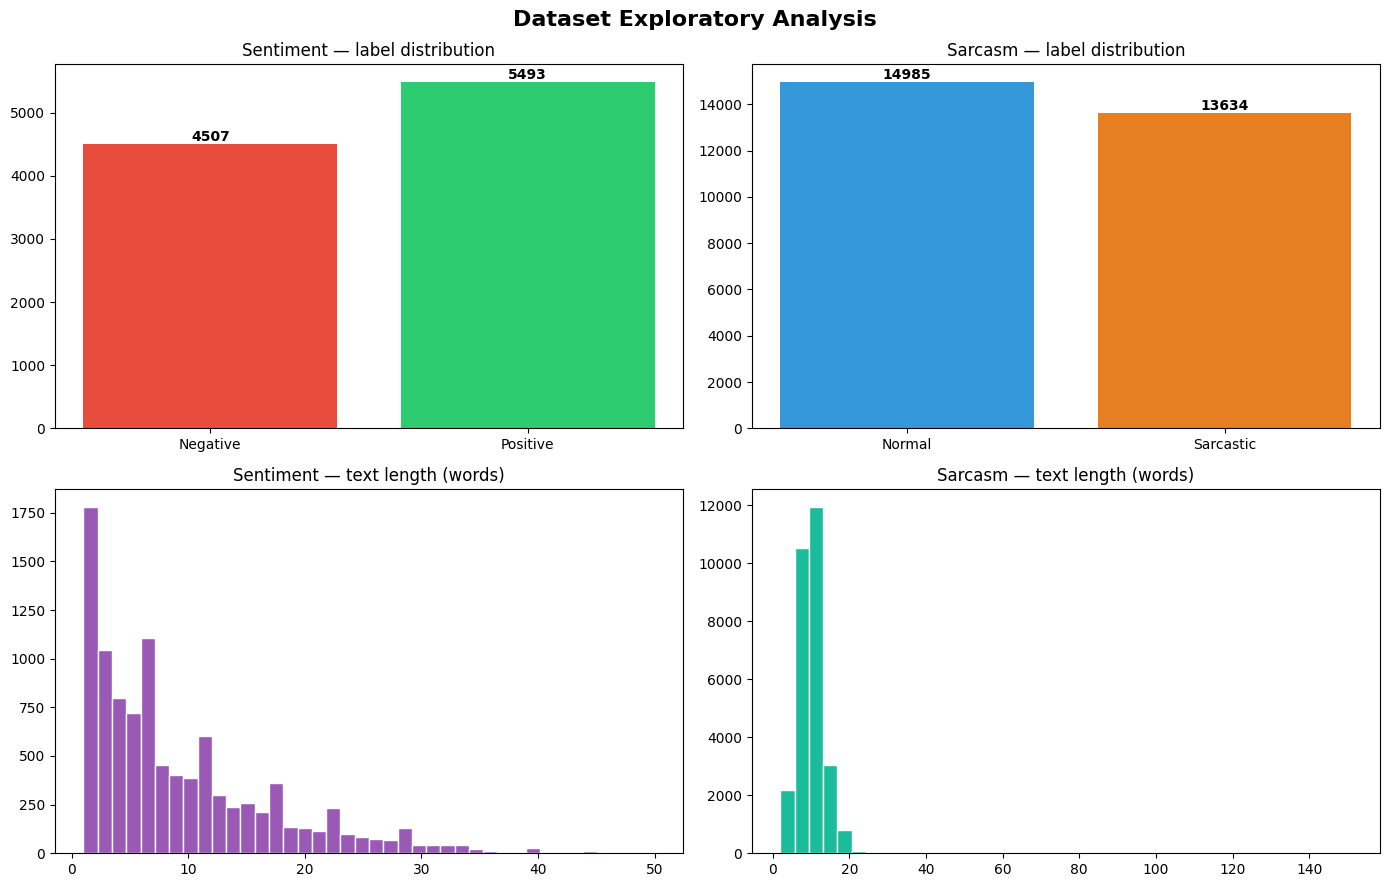

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Dataset Exploratory Analysis", fontsize=16, fontweight="bold")
cfgs = {"sentiment": (["Negative", "Positive"], ["#e74c3c", "#2ecc71"], "#9b59b6"),
        "sarcasm":   (["Normal", "Sarcastic"], ["#3498db", "#e67e22"], "#1abc9c")}
for j, (task, (names, cols, hcol)) in enumerate(cfgs.items()):
    d = DATA[task]
    counts = d["label"].value_counts().sort_index()
    axes[0, j].bar(names, counts.values, color=cols)
    axes[0, j].set_title(f"{task.capitalize()} — label distribution")
    for i, v in enumerate(counts.values):
        axes[0, j].text(i, v, str(v), ha="center", va="bottom", fontweight="bold")
    axes[1, j].hist(d["text"].str.split().str.len(), bins=40, color=hcol, edgecolor="white")
    axes[1, j].set_title(f"{task.capitalize()} — text length (words)")
plt.tight_layout(); plt.savefig("eda_datasets.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Preprocessing & Splits

In [57]:
def clean_text(text):
    """Light cleaning: keeps case & punctuation (useful signals for sarcasm + cased models)."""
    text = str(text).strip()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    return re.sub(r"\s+", " ", text)

def make_splits(df, seed=CFG["seed"]):
    X, y = df["text"].map(clean_text).tolist(), df["label"].tolist()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=0.1, random_state=seed, stratify=y_tr)
    return dict(X_tr=X_tr, y_tr=y_tr, X_va=X_va, y_va=y_va, X_te=X_te, y_te=y_te)

SPLITS = {t: make_splits(d) for t, d in DATA.items()}
for t, s in SPLITS.items():
    print(f"{t:9s} → train {len(s['X_tr'])} | val {len(s['X_va'])} | test {len(s['X_te'])}")

sentiment → train 7200 | val 800 | test 2000
sarcasm   → train 20605 | val 2290 | test 5724


## 4. Evaluation helpers + Classical baselines

In [58]:
results = {}

def get_mem():
    return psutil.Process(os.getpid()).memory_info().rss / 1e6

def evaluate_model(name, y_true, y_pred, train_time, mem_mb, task):
    r = dict(model=name, task=task,
             accuracy=accuracy_score(y_true, y_pred),
             precision=precision_score(y_true, y_pred, average="weighted", zero_division=0),
             recall=recall_score(y_true, y_pred, average="weighted", zero_division=0),
             f1=f1_score(y_true, y_pred, average="weighted", zero_division=0),
             train_time_sec=train_time, memory_mb=mem_mb)
    results[f"{task}_{name}"] = r
    print(f"\n{name} ({task})  "
          f"acc={r['accuracy']:.4f} | prec={r['precision']:.4f} | rec={r['recall']:.4f} | "
          f"F1={r['f1']:.4f} | time={train_time:.1f}s | mem={mem_mb:.0f} MB")
    return r

def tfidf():
    return TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), sublinear_tf=True)

CLASSICAL = {
    "TF-IDF+SVM": lambda: Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(C=1.0, max_iter=2000))]),
    "TF-IDF+LR":  lambda: Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=1.0, max_iter=1000))]),
}
classical_models = {}   # kept for the demo fallback

for name, make in CLASSICAL.items():
    for task, s in SPLITS.items():
        pipe = make()
        m0, t0 = get_mem(), time.time()
        pipe.fit(s["X_tr"], s["y_tr"])
        dt, dm = time.time() - t0, get_mem() - m0
        classical_models[(name, task)] = pipe
        evaluate_model(name, s["y_te"], pipe.predict(s["X_te"]), dt, dm, task)
print("\nClassical baselines done.")


TF-IDF+SVM (sentiment)  acc=0.8210 | prec=0.8208 | rec=0.8210 | F1=0.8206 | time=0.3s | mem=0 MB

TF-IDF+SVM (sarcasm)  acc=0.8567 | prec=0.8568 | rec=0.8567 | F1=0.8568 | time=1.2s | mem=0 MB

TF-IDF+LR (sentiment)  acc=0.8010 | prec=0.8041 | rec=0.8010 | F1=0.7987 | time=1.0s | mem=0 MB

TF-IDF+LR (sarcasm)  acc=0.8442 | prec=0.8445 | rec=0.8442 | F1=0.8442 | time=2.5s | mem=0 MB

Classical baselines done.


## 5. Transformer fine-tuning helper

In [59]:
metric_acc, metric_f1 = evaluate.load("accuracy"), evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": metric_acc.compute(predictions=preds, references=labels)["accuracy"],
            "f1": metric_f1.compute(predictions=preds, references=labels, average="weighted")["f1"]}

def to_hf(tokenizer, X, y):
    ds = HFDataset.from_dict({"text": X, "labels": y})
    # no padding here → DataCollatorWithPadding pads per batch (faster, less RAM)
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=CFG["max_len"]),
                  batched=True, remove_columns=["text"])

def fine_tune_transformer(model_name, short_name, task):
    s = SPLITS[task]
    print(f"\n{'='*60}\nFine-tuning {short_name} on {task}\n{'='*60}")
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    train_ds, val_ds, test_ds = (to_hf(tok, s[f"X_{k}"], s[f"y_{k}"]) for k in ("tr", "va", "te"))

    out_dir = f"./outputs/{short_name}_{task}"
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=CFG["epochs"],
        per_device_train_batch_size=CFG["batch_size"], per_device_eval_batch_size=64,
        learning_rate=CFG["lr"], weight_decay=0.01, warmup_ratio=0.1,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1",
        logging_steps=50, fp16=(DEVICE == "cuda"), report_to="none", seed=CFG["seed"])
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    m0, t0 = get_mem(), time.time()
    trainer.train()
    dt = time.time() - t0
    dm = torch.cuda.max_memory_allocated() / 1e6 if DEVICE == "cuda" else get_mem() - m0

    y_pred = np.argmax(trainer.predict(test_ds).predictions, axis=-1)
    print(classification_report(s["y_te"], y_pred, target_names=["class 0", "class 1"]))
    r = evaluate_model(short_name, s["y_te"], y_pred, dt, dm, task)
    r["confusion_matrix"] = confusion_matrix(s["y_te"], y_pred).tolist()
    r["history"] = trainer.state.log_history

    trainer.save_model(out_dir); tok.save_pretrained(out_dir)   # model + tokenizer for the demo
    del model, trainer
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return y_pred

## 6. Run: DistilBERT → BERT → RoBERTa

In [60]:
import inspect

metric_acc, metric_f1 = evaluate.load("accuracy"), evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": metric_acc.compute(predictions=preds, references=labels)["accuracy"],
            "f1": metric_f1.compute(predictions=preds, references=labels, average="weighted")["f1"]}

def to_hf(tokenizer, X, y):
    ds = HFDataset.from_dict({"text": X, "labels": y})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=CFG["max_len"]),
                  batched=True, remove_columns=["text"])

def make_args(out_dir):
    kw = dict(
        output_dir=out_dir, num_train_epochs=CFG["epochs"],
        per_device_train_batch_size=CFG["batch_size"], per_device_eval_batch_size=64,
        learning_rate=CFG["lr"], weight_decay=0.01,
        save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1",
        logging_steps=50, fp16=(DEVICE == "cuda"),
        report_to="none", seed=CFG["seed"])
    ok = inspect.signature(TrainingArguments.__init__).parameters
    kw["eval_strategy" if "eval_strategy" in ok else "evaluation_strategy"] = "epoch"
    if "warmup_ratio" in ok: kw["warmup_ratio"] = 0.1
    else:                    kw["warmup_steps"] = 0.1      # float = ratio in recent versions
    dropped = [k for k in kw if k not in ok]
    for k in dropped: kw.pop(k)
    if dropped: print("Warning: Ignored unsupported TrainingArguments:", dropped)
    return TrainingArguments(**kw)

def fine_tune_transformer(model_name, short_name, task):
    s = SPLITS[task]
    print(f"\n{'='*60}\nFine-tuning {short_name} on {task}\n{'='*60}")
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    train_ds, val_ds, test_ds = (to_hf(tok, s[f"X_{k}"], s[f"y_{k}"]) for k in ("tr", "va", "te"))

    out_dir = f"./outputs/{short_name}_{task}"
    args = make_args(out_dir)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    m0, t0 = get_mem(), time.time()
    trainer.train()
    dt = time.time() - t0
    dm = torch.cuda.max_memory_allocated() / 1e6 if DEVICE == "cuda" else get_mem() - m0

    y_pred = np.argmax(trainer.predict(test_ds).predictions, axis=-1)
    print(classification_report(s["y_te"], y_pred, target_names=["class 0", "class 1"]))
    r = evaluate_model(short_name, s["y_te"], y_pred, dt, dm, task)
    r["confusion_matrix"] = confusion_matrix(s["y_te"], y_pred).tolist()
    r["history"] = trainer.state.log_history

    trainer.save_model(out_dir); tok.save_pretrained(out_dir)
    del model, trainer
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return y_pred

## 7. Zero-shot NLI (no fine-tuning)

In [61]:
zs = hf_pipeline("zero-shot-classification", model="cross-encoder/nli-distilroberta-base",
                 device=0 if DEVICE == "cuda" else -1)

ZS_SETUP = {  # task: (candidate labels → class id, hypothesis template)
    "sentiment": ({"positive": 1, "negative": 0}, "The sentiment of this review is {}."),
    "sarcasm":   ({"sarcastic": 1, "serious": 0},  "This headline is {}."),
}

def zero_shot_predict(texts, labels, template, batch_size=32):
    preds = []
    for i in range(0, len(texts), batch_size):
        out = zs(texts[i:i+batch_size], list(labels), hypothesis_template=template, multi_label=False)
        out = [out] if isinstance(out, dict) else out
        preds += [labels[o["labels"][0]] for o in out]
    return preds

N = CFG["n_zero_shot"]
for task, (labels, template) in ZS_SETUP.items():
    s = SPLITS[task]
    t0 = time.time()
    y_pred = zero_shot_predict(s["X_te"][:N], labels, template)
    evaluate_model("Zero-shot NLI", s["y_te"][:N], y_pred, time.time() - t0, 0, task)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Zero-shot NLI (sentiment)  acc=0.8360 | prec=0.8475 | rec=0.8360 | F1=0.8364 | time=41.9s | mem=0 MB

Zero-shot NLI (sarcasm)  acc=0.5140 | prec=0.5101 | rec=0.5140 | F1=0.5108 | time=41.4s | mem=0 MB


## 8. Comparative results

In [62]:
df_res = pd.DataFrame(results.values())
cols = ["model", "task", "accuracy", "precision", "recall", "f1", "train_time_sec", "memory_mb"]
print(df_res[cols].round(4).to_string(index=False))

        model      task  accuracy  precision  recall     f1  train_time_sec  memory_mb
   TF-IDF+SVM sentiment    0.8210     0.8208  0.8210 0.8206          0.3108     0.0000
   TF-IDF+SVM   sarcasm    0.8567     0.8568  0.8567 0.8568          1.1765     0.0041
    TF-IDF+LR sentiment    0.8010     0.8041  0.8010 0.7987          1.0258     0.0369
    TF-IDF+LR   sarcasm    0.8442     0.8445  0.8442 0.8442          2.5350     0.4301
Zero-shot NLI sentiment    0.8360     0.8475  0.8360 0.8364         41.8848     0.0000
Zero-shot NLI   sarcasm    0.5140     0.5101  0.5140 0.5108         41.4261     0.0000


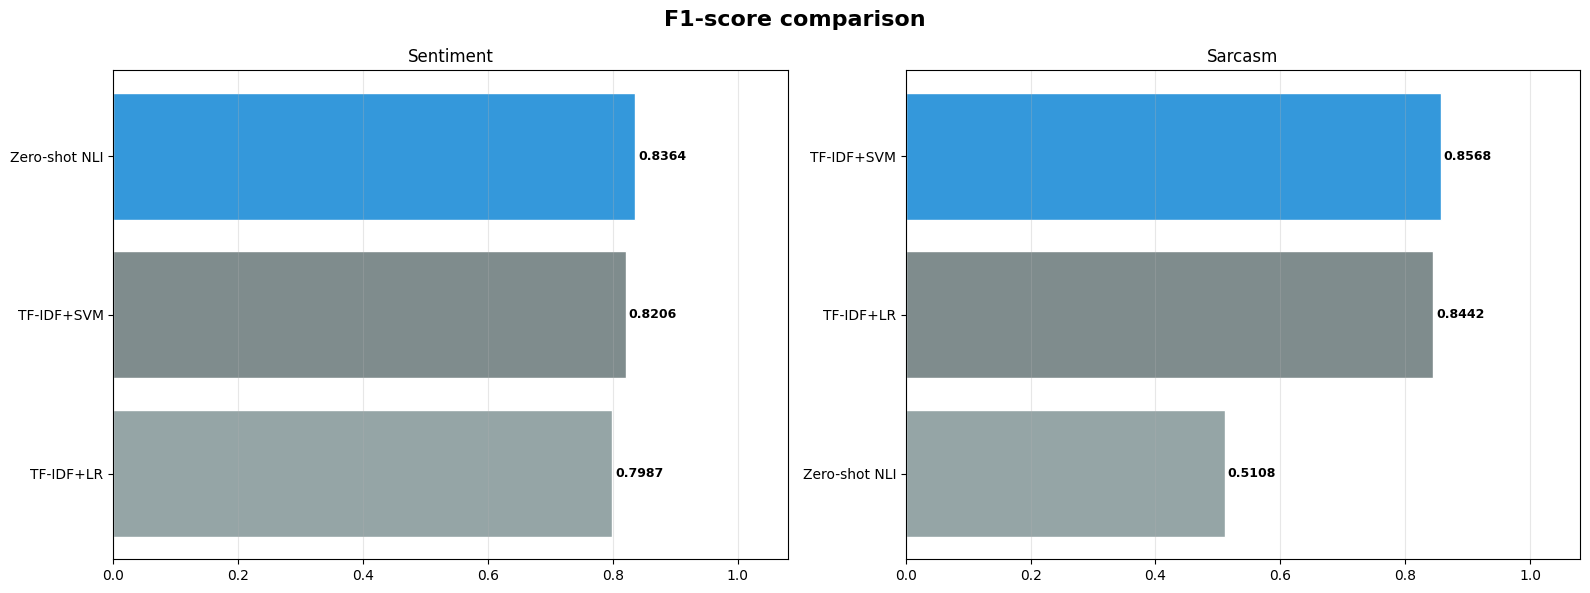

In [63]:
pal = ["#95a5a6", "#7f8c8d", "#3498db", "#2980b9", "#e74c3c", "#c0392b", "#f39c12"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("F1-score comparison", fontsize=16, fontweight="bold")
for ax, task in zip(axes, TASKS):
    sub = df_res[df_res.task == task].sort_values("f1")
    bars = ax.barh(sub["model"], sub["f1"], color=pal[:len(sub)], edgecolor="white")
    ax.set_xlim(0, 1.08); ax.set_title(task.capitalize()); ax.grid(axis="x", alpha=.3)
    for b, v in zip(bars, sub["f1"]):
        ax.text(v + .005, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontweight="bold", fontsize=9)
plt.tight_layout(); plt.savefig("f1_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

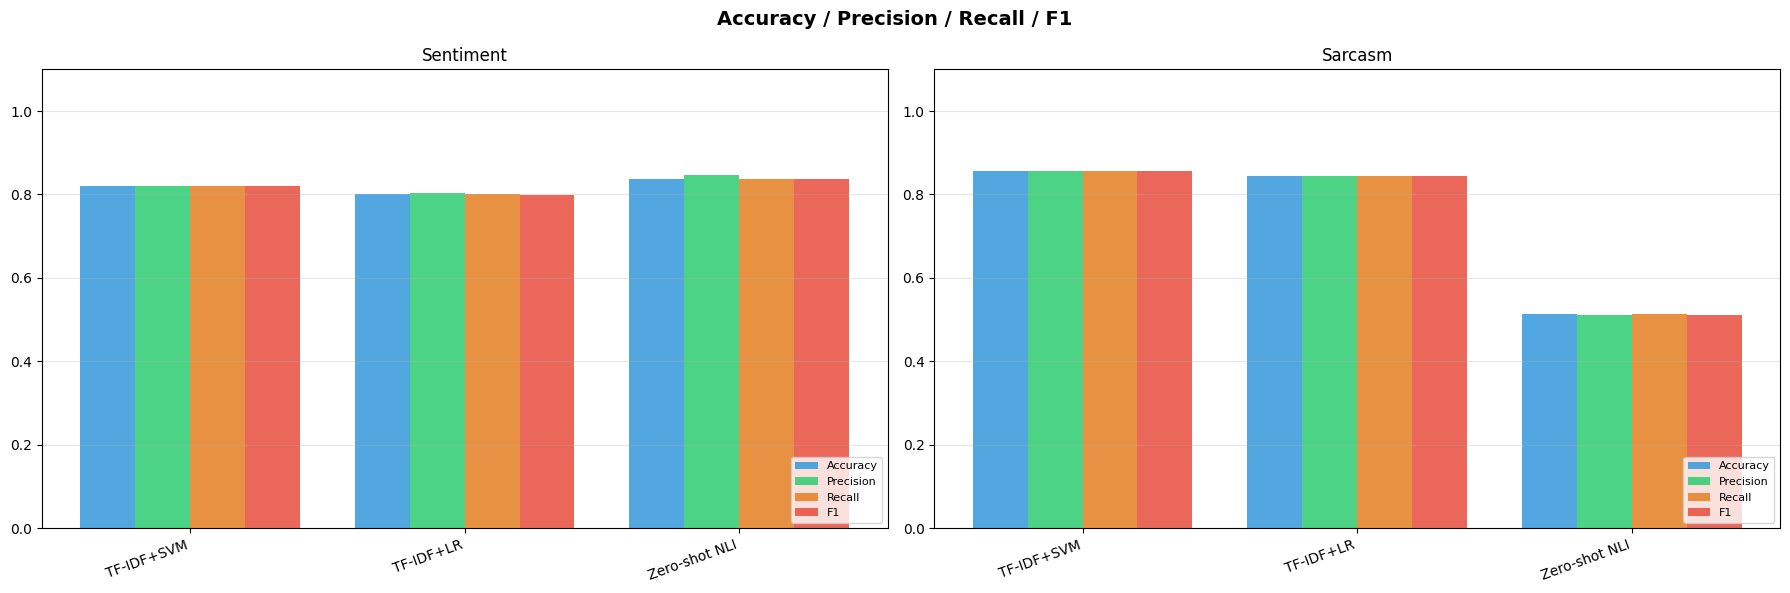

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle("Accuracy / Precision / Recall / F1", fontsize=14, fontweight="bold")
mets, mcols = ["accuracy", "precision", "recall", "f1"], ["#3498db", "#2ecc71", "#e67e22", "#e74c3c"]
for ax, task in zip(axes, TASKS):
    sub = df_res[df_res.task == task].reset_index(drop=True)
    x = np.arange(len(sub))
    for i, (m, c) in enumerate(zip(mets, mcols)):
        ax.bar(x + i*.2, sub[m], .2, label=m.capitalize(), color=c, alpha=.85)
    ax.set_xticks(x + .3); ax.set_xticklabels(sub["model"], rotation=20, ha="right")
    ax.set_ylim(0, 1.1); ax.set_title(task.capitalize()); ax.legend(loc="lower right", fontsize=8)
    ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("metrics_grouped.png", dpi=150, bbox_inches="tight"); plt.show()

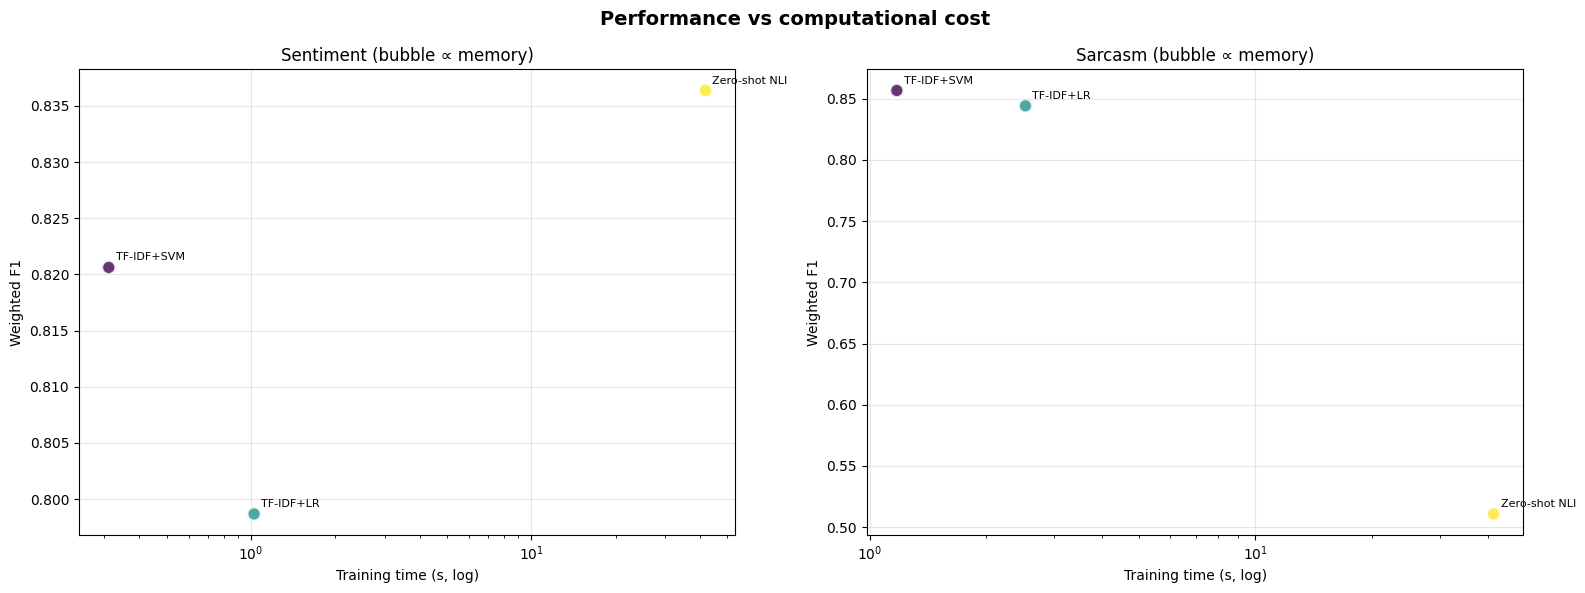

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Performance vs computational cost", fontsize=14, fontweight="bold")
for ax, task in zip(axes, TASKS):
    sub = df_res[df_res.task == task].reset_index(drop=True)
    ax.scatter(sub["train_time_sec"].clip(lower=0.1), sub["f1"],
               s=sub["memory_mb"].clip(50, 2000) / 5 + 80, c=range(len(sub)),
               cmap="viridis", alpha=.8, edgecolors="white", linewidths=1.5)
    for _, r in sub.iterrows():
        ax.annotate(r["model"], (max(r["train_time_sec"], 0.1), r["f1"]),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("Training time (s, log)"); ax.set_ylabel("Weighted F1")
    ax.set_title(f"{task.capitalize()} (bubble ∝ memory)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("tradeoff.png", dpi=150, bbox_inches="tight"); plt.show()

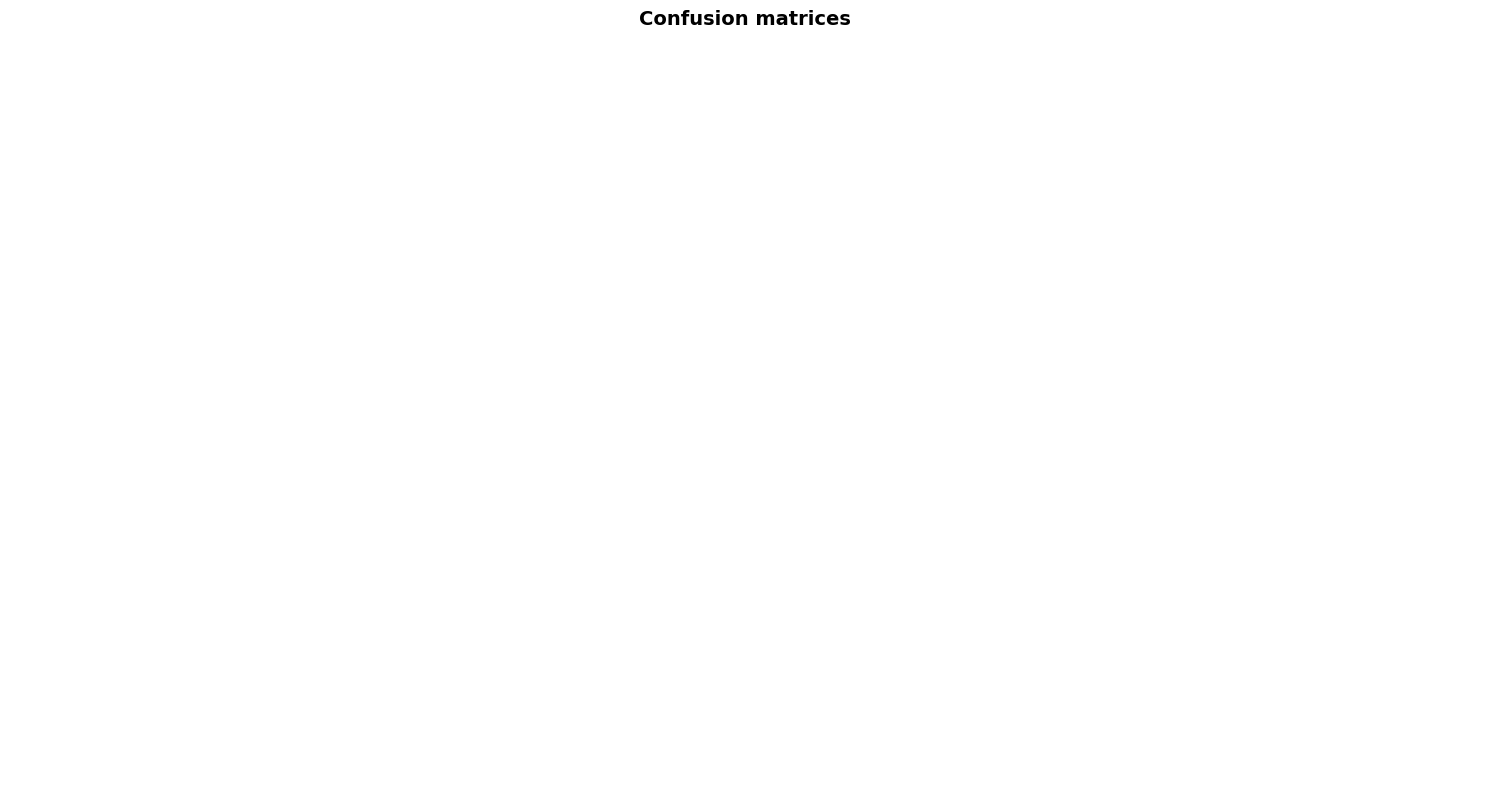

In [66]:
tm = list(CFG["models"])
fig, axes = plt.subplots(2, len(tm), figsize=(5*len(tm), 8))
fig.suptitle("Confusion matrices", fontsize=14, fontweight="bold")
for r, task in enumerate(TASKS):
    for c, m in enumerate(tm):
        ax, key = axes[r, c], f"{task}_{m}"
        if key in results and "confusion_matrix" in results[key]:
            sns.heatmap(np.array(results[key]["confusion_matrix"]), annot=True, fmt="d",
                        cmap="Blues", cbar=False, ax=ax)
            ax.set_title(f"{m} ({task})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        else:
            ax.axis("off")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

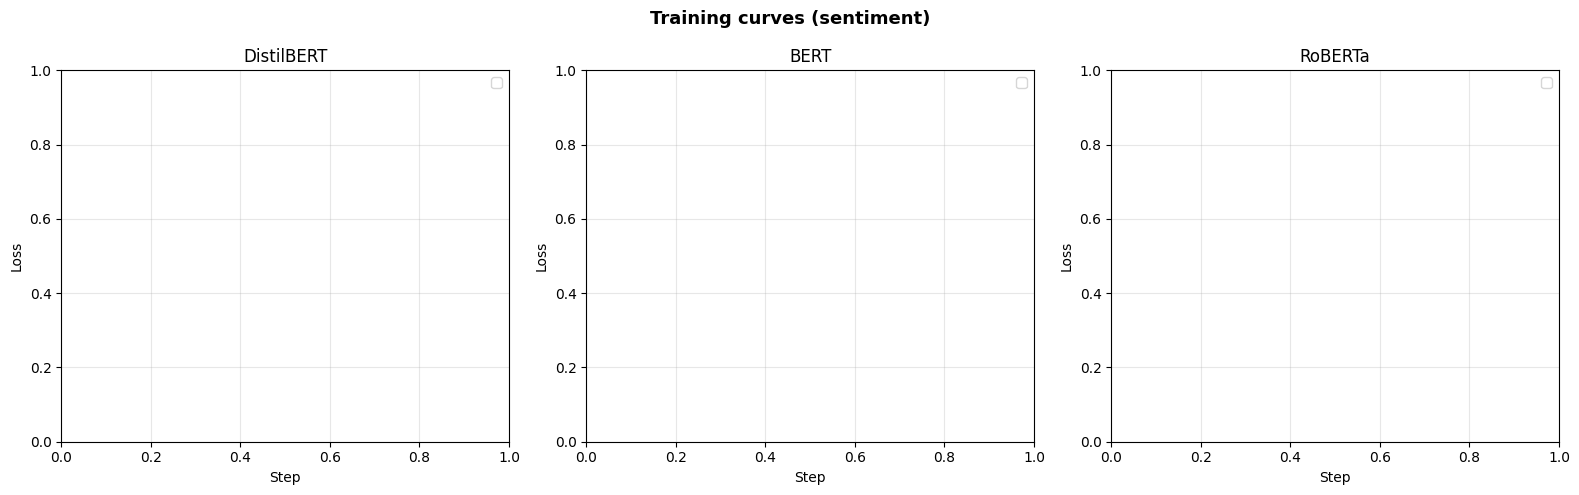

In [67]:
fig, axes = plt.subplots(1, len(tm), figsize=(5.3*len(tm), 5))
fig.suptitle("Training curves (sentiment)", fontsize=13, fontweight="bold")
for ax, m in zip(np.atleast_1d(axes), tm):
    hist = results.get(f"sentiment_{m}", {}).get("history", [])
    tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    if tr: ax.plot(*zip(*tr), label="train", color="#3498db")
    if ev: ax.plot(*zip(*ev), label="val", color="#e74c3c", marker="o")
    ax.set_title(m); ax.set_xlabel("Step"); ax.set_ylabel("Loss"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Sarcasm error analysis

In [68]:
@torch.no_grad()
def batch_predict(model_dir, texts, batch_size=64):
    tok = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir).eval().to(DEVICE)
    preds = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i+batch_size], truncation=True, padding=True,
                  max_length=CFG["max_len"], return_tensors="pt").to(DEVICE)
        preds += model(**enc).logits.argmax(-1).cpu().tolist()
    return preds

best_dir = "./outputs/RoBERTa_sarcasm"
if os.path.exists(best_dir):
    s = SPLITS["sarcasm"]
    texts, labels = s["X_te"][:500], s["y_te"][:500]
    preds = batch_predict(best_dir, texts)
    fp = [t for t, y, p in zip(texts, labels, preds) if p == 1 and y == 0]
    fn = [t for t, y, p in zip(texts, labels, preds) if p == 0 and y == 1]
    print(f"False positives ({len(fp)}) — flagged sarcastic but normal:")
    for t in fp[:5]: print("  •", t)
    print(f"\nFalse negatives ({len(fn)}) — missed sarcasm:")
    for t in fn[:5]: print("  •", t)
else:
    print("Warning: RoBERTa sarcasm model not found — run section 6 first.")

## 10. Save results

In [69]:
df_out = df_res[cols]
df_out.to_csv("project1_results.csv", index=False)
print("Saved → project1_results.csv\n" + "="*70)
for task in TASKS:
    sub = df_out[df_out.task == task].sort_values("f1", ascending=False).reset_index(drop=True)
    print(f"\n{task.upper()}")
    for i, r in sub.iterrows():
        print(f"  {i+1}. {r['model']:<14s} F1={r['f1']:.4f}  acc={r['accuracy']:.4f}")

Saved → project1_results.csv

SENTIMENT
  1. Zero-shot NLI  F1=0.8364  acc=0.8360
  2. TF-IDF+SVM     F1=0.8206  acc=0.8210
  3. TF-IDF+LR      F1=0.7987  acc=0.8010

SARCASM
  1. TF-IDF+SVM     F1=0.8568  acc=0.8567
  2. TF-IDF+LR      F1=0.8442  acc=0.8442
  3. Zero-shot NLI  F1=0.5108  acc=0.5140


## 11. Predictor
Takes a sentence and returns sentiment and sarcasm predictions with confidence bars and a short verdict.
Uses the fine-tuned **RoBERTa** if available, otherwise falls back to **TF-IDF + LR**.

In [70]:
LANG = "fr"   # "fr" or "en"

T = {
 "fr": dict(pos="Positif", neg="Négatif", sar="Sarcastique", nosar="Sincère",
            h_ok="Sentiment positif, ton sincère", h_bad="Sentiment négatif, ton sincère",
            h_sar_pos="Positif en apparence, mais sarcastique",
            h_sar_neg="Négatif et sarcastique",
            low="Confiance faible", empty="Entrée vide"),
 "en": dict(pos="Positive", neg="Negative", sar="Sarcastic", nosar="Sincere",
            h_ok="Positive sentiment, sincere tone", h_bad="Negative sentiment, sincere tone",
            h_sar_pos="Positive on the surface, but sarcastic",
            h_sar_neg="Negative and sarcastic",
            low="Low confidence", empty="Empty input"),
}[LANG]

def bar(p, n=10):
    k = round(p * n)
    return "█" * k + "░" * (n - k)

def conf_level(p):
    return "high" if p >= .9 else "medium" if p >= .75 else "low"

class SentimentPredictor:
    def __init__(self, model_name="RoBERTa"):
        self.pipes = {}
        for task in TASKS:
            d = f"./outputs/{model_name}_{task}"
            if os.path.exists(d):
                self.pipes[task] = hf_pipeline("text-classification", model=d, tokenizer=d, top_k=None,
                                               device=0 if DEVICE == "cuda" else -1,
                                               truncation=True, max_length=CFG["max_len"])
                print(f"{task}: {model_name} loaded")
            else:
                self.pipes[task] = classical_models[("TF-IDF+LR", task)]
                print(f"{task}: fallback TF-IDF+LR")

    def p_positive(self, task, text):
        """P(class 1) for the given task."""
        pipe = self.pipes[task]
        if isinstance(pipe, Pipeline):
            return float(pipe.predict_proba([text])[0][1])
        out = pipe(text)
        out = out[0] if isinstance(out[0], list) else out
        return float(next(o["score"] for o in out if o["label"].endswith("1")))

    def analyze(self, text):
        text = clean_text(text)
        if not text:
            return None
        ps, pz = self.p_positive("sentiment", text), self.p_positive("sarcasm", text)
        pos, sar = ps >= .5, pz >= .5
        return dict(text=text, positive=pos, sarcastic=sar,
                    p_sentiment=ps if pos else 1 - ps, p_sarcasm=pz if sar else 1 - pz)

    def report(self, text):
        r = self.analyze(text)
        if r is None:
            print(T["empty"]); return
        s_lb = T["pos"] if r["positive"] else T["neg"]
        z_lb = T["sar"] if r["sarcastic"] else T["nosar"]
        if r["sarcastic"]:
            verdict = T["h_sar_pos"] if r["positive"] else T["h_sar_neg"]
        else:
            verdict = T["h_ok"] if r["positive"] else T["h_bad"]
        print(f"\n\"{r['text']}\"")
        print(f"  {s_lb:<12s} {bar(r['p_sentiment'])} {r['p_sentiment']:.0%} ({conf_level(r['p_sentiment'])})")
        print(f"  {z_lb:<12s} {bar(r['p_sarcasm'])} {r['p_sarcasm']:.0%} ({conf_level(r['p_sarcasm'])})")
        print(f"  -> {verdict}")
        if min(r["p_sentiment"], r["p_sarcasm"]) < .6:
            print(f"  Note: {T['low']}")

predictor = SentimentPredictor()
for s in ["This movie was absolutely wonderful, I loved every minute!",
          "Oh great, another Monday. Just what I needed.",
          "Man bites dog, local government announces plan to fix potholes by 2090",
          "The service was terrible and the food was cold."]:
    predictor.report(s)

sentiment: fallback TF-IDF+LR
sarcasm: fallback TF-IDF+LR

"This movie was absolutely wonderful, I loved every minute!"
  Négatif      ██████░░░░ 57% (low)
  Sincère      ██████░░░░ 57% (low)
  -> Sentiment négatif, ton sincère
  Note: Confiance faible

"Oh great, another Monday. Just what I needed."
  Négatif      ██████░░░░ 58% (low)
  Sincère      ██████░░░░ 59% (low)
  -> Sentiment négatif, ton sincère
  Note: Confiance faible

"Man bites dog, local government announces plan to fix potholes by 2090"
  Positif      █████░░░░░ 51% (low)
  Sarcastique  ██████████ 98% (high)
  -> Positif en apparence, mais sarcastique
  Note: Confiance faible

"The service was terrible and the food was cold."
  Négatif      ███████░░░ 66% (low)
  Sincère      ██████████ 99% (high)
  -> Sentiment négatif, ton sincère


In [71]:

import gradio as gr

custom_css = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

.gradio-container {
    background: #080d1b !important;
    font-family: 'Inter', sans-serif !important;
    color: #f8fafc !important;
}

#main-container {
    max-width: 1100px;
    margin: auto;
}

.hero {
    text-align: center;
    padding: 45px 20px 30px;
}

.hero h1 {
    font-size: 38px;
    font-weight: 800;
    letter-spacing: -1.5px;
    background: linear-gradient(90deg, #a78bfa, #38bdf8);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
    margin-bottom: 12px;
}

.hero p {
    color: #94a3b8;
    font-size: 15px;
}

.model-tag {
    display: inline-block;
    padding: 8px 15px;
    border: 1px solid #334155;
    border-radius: 30px;
    background: #151e32;
    color: #a5b4fc;
    font-size: 12px;
    margin-top: 12px;
}

.panel {
    background: linear-gradient(145deg, #151e32, #101729);
    border: 1px solid #26334d;
    border-radius: 20px;
    padding: 24px;
}

.section-title {
    color: #f8fafc;
    font-size: 17px;
    font-weight: 700;
    margin-bottom: 15px;
}

textarea {
    background: #0b1222 !important;
    color: #f8fafc !important;
    border: 1px solid #334155 !important;
    border-radius: 14px !important;
    font-size: 15px !important;
}

textarea:focus {
    border-color: #818cf8 !important;
    box-shadow: 0 0 0 2px #818cf833 !important;
}

.primary-btn {
    background: linear-gradient(90deg, #7c3aed, #2563eb) !important;
    border: none !important;
    border-radius: 12px !important;
    color: white !important;
    font-weight: 700 !important;
    min-height: 48px !important;
    transition: 0.3s !important;
}

.primary-btn:hover {
    filter: brightness(1.15);
    transform: translateY(-2px);
}

.result-title {
    color: #c4b5fd;
    font-size: 16px;
    font-weight: 700;
}

.verdict-box textarea {
    background: #0b1222 !important;
}

footer {
    display: none !important;
}

"""

with gr.Blocks(
    title="Sentiment & Sarcasm AI",
    theme=gr.themes.Base(
        primary_hue="violet",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css
) as demo:

    with gr.Column(elem_id="main-container"):

        gr.HTML("""
        <div class="hero">
            <h1>Sentiment & Sarcasm AI</h1>
            <p>Understand emotions and detect sarcasm using Artificial Intelligence.</p>
            <div class="model-tag">
                ✦ Powered by Fine-tuned RoBERTa
            </div>
        </div>
        """)

        with gr.Column(elem_classes="panel"):

            gr.HTML('<div class="section-title">✍️ Enter your text</div>')

            inp = gr.Textbox(
                label="Your sentence",
                lines=5,
                placeholder="Write something here to analyze its sentiment and sarcasm..."
                )

            btn = gr.Button(
                "✦ Analyze Text",
                variant="primary",
                elem_classes="primary-btn"
            )

            gr.Examples(
                examples=[
                    ["This movie was absolutely wonderful, I loved every minute!"],
                    ["Oh great, another Monday. Just what I needed."],
                    ["Man bites dog, local government announces plan to fix potholes by 2090"],
                    ["The service was terrible and the food was cold."]
                ],
                inputs=inp
            )

        gr.HTML("""
        <div style="margin:30px 0 15px; font-size:20px;
                    font-weight:700; color:#f8fafc;">
            Analysis Results
        </div>
        """)

        with gr.Row():

            with gr.Column(elem_classes="panel"):
                gr.HTML('<div class="result-title">💬 Sentiment Analysis</div>')
                out_s = gr.Label(
                    label="Sentiment probability",
                    num_top_classes=2
                )

            with gr.Column(elem_classes="panel"):
                gr.HTML('<div class="result-title">🎭 Sarcasm Detection</div>')
                out_z = gr.Label(
                    label="Sarcasm probability",
                    num_top_classes=2
                )

        with gr.Column(elem_classes="panel"):
            gr.HTML('<div class="result-title">🤖 AI Interpretation</div>')
            out_v = gr.Textbox(
                label="Final verdict",
                interactive=False,
                lines=2,
                elem_classes="verdict-box"
            )

        gr.HTML("""
        <div style="text-align:center; padding:35px 10px;
                    color:#64748b; font-size:12px;">
            Sentiment & Sarcasm AI · NLP Research Project
            <br><br>
            Built with Python, Gradio & Transformers
        </div>
        """)

    btn.click(
        fn=ui_predict,
        inputs=inp,
        outputs=[out_s, out_z, out_v]
    )

    inp.submit(
        fn=ui_predict,
        inputs=inp,
        outputs=[out_s, out_z, out_v]
    )

demo.launch(share=True)


* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://ffe702aa7417d0da29.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
